In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
n = 100

house_size = 1000 + np.random.rand(n) * 2000 # 1000 -> 3000
house_age = np.random.randint(0, 30, n)
distance = 1 + np.random.rand(n) * 20 # between 1 to 21 km

house_price = (100_000 +
               150 * house_size -
               2_000 * house_age -
               10_000 * distance +
               np.random.normal(0, 30_000, n))


house_data = pd.DataFrame({
    'Size (sqf)': house_size,
    'Age (yrs)': house_age,
    'Dist (to city)': distance,
    'Price ($)': house_price
})

In [25]:
house_data.to_csv('house_data.csv', index=False)

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [27]:
df = pd.read_csv ('house_data.csv')

In [28]:
X = df[['Size (sqf)', 'Age (yrs)', 'Dist (to city)']].values # features
y = df['Price ($)'].values # target

In [29]:
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

In [30]:
X_with_intercept = np.column_stack((np.ones(len(X_scaled)), X_scaled))
beta = np.linalg.inv(X_with_intercept.T @ X_with_intercept) @ X_with_intercept.T @ y
intercept = beta[0]
coefficients = beta[1:]

In [31]:
y_pred = X_with_intercept @ beta

In [32]:
# MSE
loss = np.mean((y_pred - y) ** 2)

In [33]:
print (f'Intercept: {intercept} and Coefficients: {coefficients} and Loss: {loss}')


Intercept: 258540.03274696847 and Coefficients: [ 90450.90297859 -16430.00906618 -48915.23525098] and Loss: 680102570.0377461


In [34]:
# X = df[['Size (sqf)', 'Age (yrs)', 'Dist (to city)']].values # features
# y = df['Price ($)'].values # target

In [35]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.coefficients = None
        self.intercept = None
        self.loss_history = [] # This is only for visualization

    def fit (self, X, y):
        n_samples, n_features = X.shape
        X_with_intercept = np.column_stack((np.ones(n_samples), X_scaled))
        beta = np.zeros(n_features + 1)

        for iteration in range(self.n_iterations):
            y_pred  = X_with_intercept @ beta

            residual = y_pred - y
            loss = np.mean(residual ** 2)
            self.loss_history.append(loss)

            gradient = (2 / n_samples) * X_with_intercept.T @ residual
            beta -= self.learning_rate * gradient

        self.intercept = beta[0]
        self.coefficients = beta[1:]

    def predict (self, X):
        return self.intercept + X @ self.coefficients


In [36]:
model = LinearRegressionGD(learning_rate=0.1, n_iterations=30)
model.fit(X, y)

In [37]:
model.intercept

np.float64(258219.97568867283)

In [38]:
model.coefficients

array([ 90356.86683835, -16397.75923875, -48869.48292855])

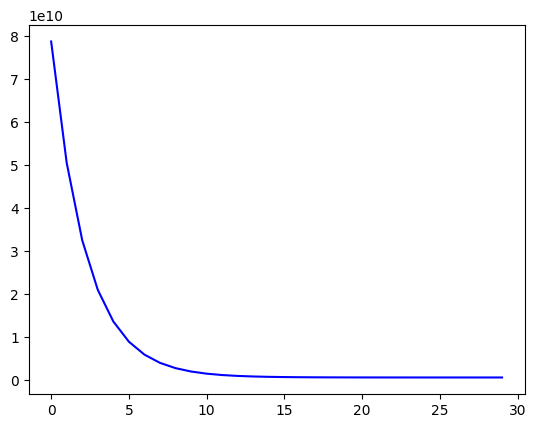

In [39]:
plt.plot (model.loss_history, color='blue')